LOAD AND INSPECT THE DATA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully")

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully


In [3]:
# Load both Generation and Weather files
gen = pd.read_csv('../data/raw/Plant_1_Generation_Data.csv')
weather = pd.read_csv('../data/raw/Plant_1_Weather_Sensor_Data.csv')

print("Generation:", gen.shape)
print("Weather:", weather.shape)

Generation: (68778, 7)
Weather: (3182, 6)


In [4]:
# Inspect generation columns
print(gen.dtypes)
print()
print(gen.head(5))

DATE_TIME          str
PLANT_ID         int64
SOURCE_KEY         str
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

          DATE_TIME  PLANT_ID       SOURCE_KEY  DC_POWER  AC_POWER  \
0  15-05-2020 00:00   4135001  1BY6WEcLGh8j5v7       0.0       0.0   
1  15-05-2020 00:00   4135001  1IF53ai7Xc0U56Y       0.0       0.0   
2  15-05-2020 00:00   4135001  3PZuoBAID5Wc2HD       0.0       0.0   
3  15-05-2020 00:00   4135001  7JYdWkrLSPkdwr4       0.0       0.0   
4  15-05-2020 00:00   4135001  McdE0feGgRqW7Ca       0.0       0.0   

   DAILY_YIELD  TOTAL_YIELD  
0          0.0    6259559.0  
1          0.0    6183645.0  
2          0.0    6987759.0  
3          0.0    7602960.0  
4          0.0    7158964.0  


In [9]:
# Check for nulls and duplicates
print("=== NULLS ===")
print(gen.isnull().sum())
print("\n=== DUPLICATES ===")
print("Generation duplicates:", gen.duplicated().sum())
print("Weather duplicates:", weather.duplicated().sum())

=== NULLS ===
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

=== DUPLICATES ===
Generation duplicates: 0
Weather duplicates: 0


In [10]:
# Inspect the power values
print("AC_POWER max:", gen['AC_POWER'].max(), "kW")
print("DC_POWER max:", gen['DC_POWER'].max())  # no unit
print("Inverter count:", gen['SOURCE_KEY'].nunique())
print("Date range:", gen['DATE_TIME'].min(), "to", gen['DATE_TIME'].max())

AC_POWER max: 1410.95 kW
DC_POWER max: 14471.125
Inverter count: 22
Date range: 1/6/2020 0:00 to 9/6/2020 9:45


DATA CLEANING

In [11]:
# Fix datetime (the mixed format problem)
gen['DATE_TIME'] = pd.to_datetime(gen['DATE_TIME'], dayfirst=True, format='mixed')
weather['DATE_TIME'] = pd.to_datetime(weather['DATE_TIME'], format='mixed')

# Verify it worked
print("Gen dtype:", gen['DATE_TIME'].dtype)
print("Weather dtype:", weather['DATE_TIME'].dtype)
print()
print("Gen range:", gen['DATE_TIME'].min(), "to", gen['DATE_TIME'].max())
print("Weather range:", weather['DATE_TIME'].min(), "to", weather['DATE_TIME'].max())

Gen dtype: datetime64[us]
Weather dtype: datetime64[us]

Gen range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00
Weather range: 2020-05-15 00:00:00 to 2020-06-17 23:45:00


In [12]:
# Fix the DC_POWER unit mismatch
gen['DC_POWER'] = gen['DC_POWER'] / 1000

# Verify the fix
print("DC_POWER max after fix:", round(gen['DC_POWER'].max(), 2), "kW")
print("AC_POWER max:", round(gen['AC_POWER'].max(), 2), "kW")
print("Expected inverter efficiency (AC/DC):", 
      round(gen[gen['DC_POWER']>0]['AC_POWER'].sum() / gen[gen['DC_POWER']>0]['DC_POWER'].sum(), 4))

DC_POWER max after fix: 14.47 kW
AC_POWER max: 1410.95 kW
Expected inverter efficiency (AC/DC): 97.7951


In [13]:
# Sort by datetime
gen = gen.sort_values('DATE_TIME').reset_index(drop=True)
weather = weather.sort_values('DATE_TIME').reset_index(drop=True)

print("Sorted. First timestamp:", gen['DATE_TIME'].iloc[0])
print("Last timestamp:", gen['DATE_TIME'].iloc[-1])

Sorted. First timestamp: 2020-05-15 00:00:00
Last timestamp: 2020-06-17 23:45:00


In [14]:
# Feature engineering: adding all the date columns would be needed
# These columns will make SQL GROUP BY and Power BI slicer possible
for df in [gen, weather]:
    df['hour']        = df['DATE_TIME'].dt.hour
    df['date']        = df['DATE_TIME'].dt.date
    df['day']         = df['DATE_TIME'].dt.day
    df['month']       = df['DATE_TIME'].dt.month
    df['month_name']  = df['DATE_TIME'].dt.strftime('%B')
    df['year']        = df['DATE_TIME'].dt.year
    df['weekday']     = df['DATE_TIME'].dt.day_name()
    df['is_weekend']  = df['DATE_TIME'].dt.dayofweek >= 5
    df['week']        = df['DATE_TIME'].dt.isocalendar().week.astype(int)

# For generation only: inverter efficiency
gen['inv_efficiency'] = gen['AC_POWER'] / gen['DC_POWER'].replace(0, None)

print("New columns added:", [c for c in gen.columns if c not in 
      ['DATE_TIME','PLANT_ID','SOURCE_KEY','DC_POWER','AC_POWER','DAILY_YIELD','TOTAL_YIELD']])

New columns added: ['hour', 'date', 'day', 'month', 'month_name', 'year', 'weekday', 'is_weekend', 'week', 'inv_efficiency']


In [15]:
# Save clean files
gen.to_csv('../data/clean/clean_generation.csv', index=False)
weather.to_csv('../data/clean/clean_weather.csv', index=False)

print("Clean files saved.")
print("Generation shape:", gen.shape)
print("Weather shape:", weather.shape)

Clean files saved.
Generation shape: (68778, 17)
Weather shape: (3182, 15)


CALCULATE YOUR KPIs

In [16]:
#  KPI 1: Daily total generation across all inverters
daily_gen = gen.groupby('date')['AC_POWER'].sum() * 0.25  # kW × 0.25hr = kWh
daily_gen = daily_gen.reset_index()
daily_gen.columns = ['date', 'total_kwh']

print("Best day:", daily_gen.loc[daily_gen['total_kwh'].idxmax(), 'date'],
      "-", round(daily_gen['total_kwh'].max(), 1), "kWh")
print("Worst day:", daily_gen.loc[daily_gen['total_kwh'].idxmin(), 'date'],
      "-", round(daily_gen['total_kwh'].min(), 1), "kWh")
print("Average day:", round(daily_gen['total_kwh'].mean(), 1), "kWh")
print("Total across 34 days:", round(daily_gen['total_kwh'].sum() / 1000, 1), "MWh")

Best day: 2020-05-25 - 192894.0 kWh
Worst day: 2020-05-18 - 117742.4 kWh
Average day: 155662.2 kWh
Total across 34 days: 5292.5 MWh


In [17]:
# KPI 2: Capacity Factor
total_capacity_kw = 30460  # sum of all inverter max outputs

# Capacity factor per day
daily_gen['theoretical_kwh'] = total_capacity_kw * 24  # kW × 24hrs
daily_gen['capacity_factor'] = daily_gen['total_kwh'] / daily_gen['theoretical_kwh']

print("=== DAILY CAPACITY FACTOR ===")
print(daily_gen[['date', 'total_kwh', 'capacity_factor']].to_string())
print()
print("Average CF:", round(daily_gen['capacity_factor'].mean() * 100, 2), "%")
print("Best day CF:", round(daily_gen['capacity_factor'].max() * 100, 2), "%")
print("Worst day CF:", round(daily_gen['capacity_factor'].min() * 100, 2), "%")

=== DAILY CAPACITY FACTOR ===
          date      total_kwh  capacity_factor
0   2020-05-15  137707.739851         0.188372
1   2020-05-16  142089.955357         0.194367
2   2020-05-17  165243.847321         0.226039
3   2020-05-18  117742.427232         0.161062
4   2020-05-19  133062.622768         0.182018
5   2020-05-20  131271.141845         0.179568
6   2020-05-21  165685.612351         0.226644
7   2020-05-22  156957.526994         0.214704
8   2020-05-23  186471.071993         0.255076
9   2020-05-24  174954.452678         0.239323
10  2020-05-25  192894.040328         0.263862
11  2020-05-26  172370.942410         0.235789
12  2020-05-27  146426.963929         0.200300
13  2020-05-28  183279.863928         0.250711
14  2020-05-29  178277.656906         0.243869
15  2020-05-30  159010.798660         0.217513
16  2020-05-31  131484.793751         0.179860
17  2020-06-01  127422.874999         0.174304
18  2020-06-02  162166.892708         0.221830
19  2020-06-03  164627.100596 

In [18]:
# KPI 3: Inverter efficiency per inverter
inv_eff = gen[gen['DC_POWER'] > 0].groupby('SOURCE_KEY').apply(
    lambda x: x['AC_POWER'].sum() / x['DC_POWER'].sum()
).reset_index()
inv_eff.columns = ['inverter_id', 'mean_efficiency']
inv_eff = inv_eff.sort_values('mean_efficiency')

print("=== INVERTER EFFICIENCY ===")
print(inv_eff.to_string())
print()
print("Lowest efficiency inverter:", inv_eff.iloc[0]['inverter_id'], 
      "-", round(inv_eff.iloc[0]['mean_efficiency']*100, 2), "%")
print("Highest efficiency inverter:", inv_eff.iloc[-1]['inverter_id'],
      "-", round(inv_eff.iloc[-1]['mean_efficiency']*100, 2), "%")

=== INVERTER EFFICIENCY ===
        inverter_id  mean_efficiency
10  adLQvlD726eNBSB        97.778635
5   VHMLBKoKgIrUVDU        97.785068
2   3PZuoBAID5Wc2HD        97.785104
1   1IF53ai7Xc0U56Y        97.785212
12  iCRJl6heRkivqQ3        97.788804
21  zVJPv84UY57bAof        97.788995
17  uHbuxQJl8lW7ozc        97.789338
8   ZnxXDlPa8U1GXgE        97.789808
18  wCURE6d3bPkepu2        97.790271
7   YxYtjZvoooNbGkE        97.792439
14  pkci93gMrogZuBj        97.792670
6   WRmjgnKYAwPKWDb        97.793303
15  rGa61gmuvPhdLxV        97.793897
4   McdE0feGgRqW7Ca        97.793919
19  z9Y9gH1T5YWrNuG        97.794619
9   ZoEaEvLYb1n2sOq        97.795369
3   7JYdWkrLSPkdwr4        97.796437
20  zBIq5rxdHJRwDNY        97.797853
13  ih0vzX44oOqAx2f        97.801935
16  sjndEbLyjtCKgGv        97.803626
0   1BY6WEcLGh8j5v7        97.825807
11  bvBOhCH3iADSZry        97.836375

Lowest efficiency inverter: adLQvlD726eNBSB - 9777.86 %
Highest efficiency inverter: bvBOhCH3iADSZry - 9783.64 %


In [19]:
#  Daytime downtime hours per day
downtime = gen[
    (gen['AC_POWER'] == 0) & 
    (gen['hour'] >= 7) & 
    (gen['hour'] <= 18)
].groupby('date').size() * 0.25 / gen['SOURCE_KEY'].nunique()
# Divide by 22 inverters to get plant-level hours, not inverter×hours

downtime = downtime.reset_index()
downtime.columns = ['date', 'downtime_hours']

print("Days with daytime downtime:")
print(downtime[downtime['downtime_hours'] > 0].to_string())

Days with daytime downtime:
          date  downtime_hours
0   2020-05-15        0.522727
1   2020-05-16        0.500000
2   2020-05-17        0.500000
3   2020-05-18        0.500000
4   2020-05-19        0.795455
5   2020-05-20        0.250000
6   2020-05-21        0.340909
7   2020-05-22        0.363636
8   2020-05-23        0.250000
9   2020-05-24        0.261364
10  2020-05-25        0.261364
11  2020-05-26        0.488636
12  2020-05-27        0.170455
13  2020-05-28        0.250000
14  2020-05-29        0.181818
15  2020-05-30        0.250000
16  2020-05-31        0.250000
17  2020-06-01        0.250000
18  2020-06-02        0.159091
19  2020-06-03        0.250000
20  2020-06-04        0.113636
21  2020-06-05        0.159091
22  2020-06-06        0.227273
23  2020-06-07        0.613636
24  2020-06-08        0.250000
25  2020-06-09        0.261364
26  2020-06-10        0.500000
27  2020-06-11        0.250000
28  2020-06-12        0.250000
29  2020-06-13        0.250000
30  2020-06

In [20]:
# KPI 5: Performance Ratio using irradiance
# Aggregate generation per timestamp (sum across all 22 inverters)
gen_ts = gen.groupby('DATE_TIME')['AC_POWER'].sum().reset_index()

# Merge with weather on timestamp
merged = pd.merge(gen_ts, weather[['DATE_TIME', 'IRRADIATION', 
                                    'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']], 
                  on='DATE_TIME', how='inner')

# Performance Ratio: AC_POWER / (Irradiance × Capacity)
# Irradiation is in kW/m², system is ~30,460 kW, standard test irradiance is 1 kW/m²
merged['PR'] = merged['AC_POWER'] / (merged['IRRADIATION'] * total_capacity_kw).replace(0, None)

daily_pr = merged.groupby(merged['DATE_TIME'].dt.date)['PR'].mean()
print("=== DAILY PERFORMANCE RATIO ===")
print(daily_pr.round(4).to_string())
print()
print("Average PR:", round(daily_pr.mean() * 100, 2), "%")

=== DAILY PERFORMANCE RATIO ===
DATE_TIME
2020-05-15    0.8724
2020-05-16    0.9613
2020-05-17    0.8938
2020-05-18    0.9786
2020-05-19    0.8602
2020-05-20     0.885
2020-05-21    0.9187
2020-05-22    0.8946
2020-05-23    0.9261
2020-05-24    0.8964
2020-05-25    0.9005
2020-05-26    0.8811
2020-05-27    0.8731
2020-05-28    0.8893
2020-05-29    0.9454
2020-05-30    0.9471
2020-05-31    0.9757
2020-06-01    0.9573
2020-06-02    0.9367
2020-06-03    0.9333
2020-06-04     0.926
2020-06-05    0.9251
2020-06-06    0.9231
2020-06-07    0.9018
2020-06-08    0.9067
2020-06-09    0.9044
2020-06-10     0.941
2020-06-11    0.9994
2020-06-12    0.9625
2020-06-13    0.9124
2020-06-14    0.9276
2020-06-15    0.9191
2020-06-16    0.9396
2020-06-17    0.9809

Average PR: 92.34 %


EXPLORATORY DATA ANALYSIS (The Charts)

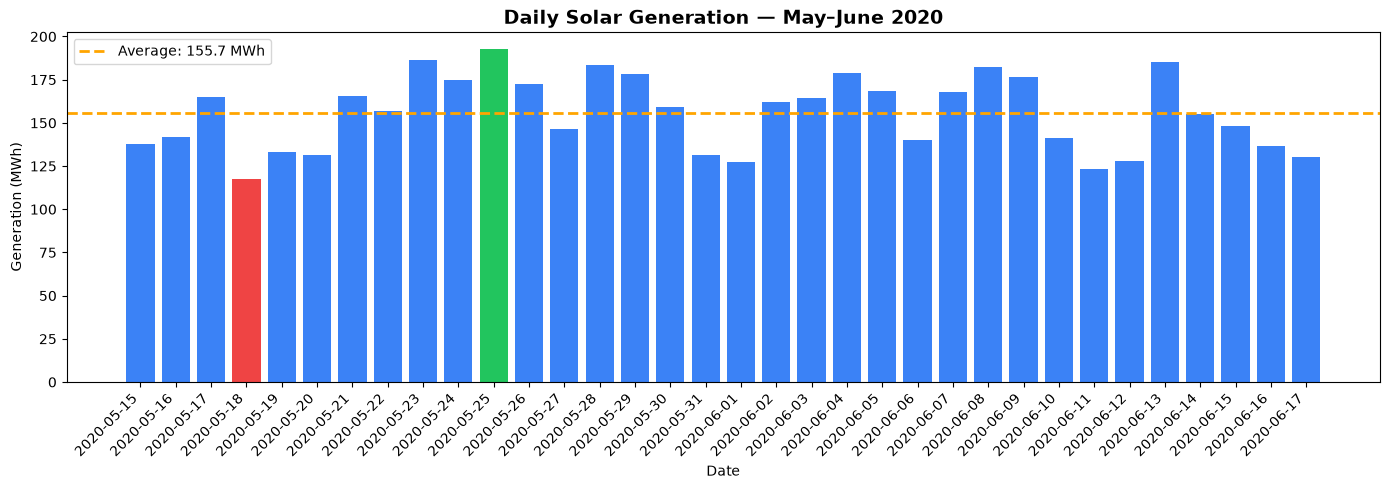

Green bar = best day. Red bar = worst day. Orange line = average.


In [21]:
# Chart 1: Daily Generation Bar Chart
fig, ax = plt.subplots(figsize=(14, 5))
colors = ['#EF4444' if v == daily_gen['total_kwh'].min() 
          else '#22C55E' if v == daily_gen['total_kwh'].max() 
          else '#3B82F6' for v in daily_gen['total_kwh']]

bars = ax.bar(daily_gen['date'].astype(str), daily_gen['total_kwh'] / 1000, color=colors)
ax.axhline(daily_gen['total_kwh'].mean() / 1000, color='orange', 
           linestyle='--', linewidth=2, label=f"Average: {daily_gen['total_kwh'].mean()/1000:.1f} MWh")
ax.set_title("Daily Solar Generation — May–June 2020", fontsize=14, fontweight='bold')
ax.set_xlabel("Date")
ax.set_ylabel("Generation (MWh)")
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../reports/chart1_daily_generation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Green bar = best day. Red bar = worst day. Orange line = average.")

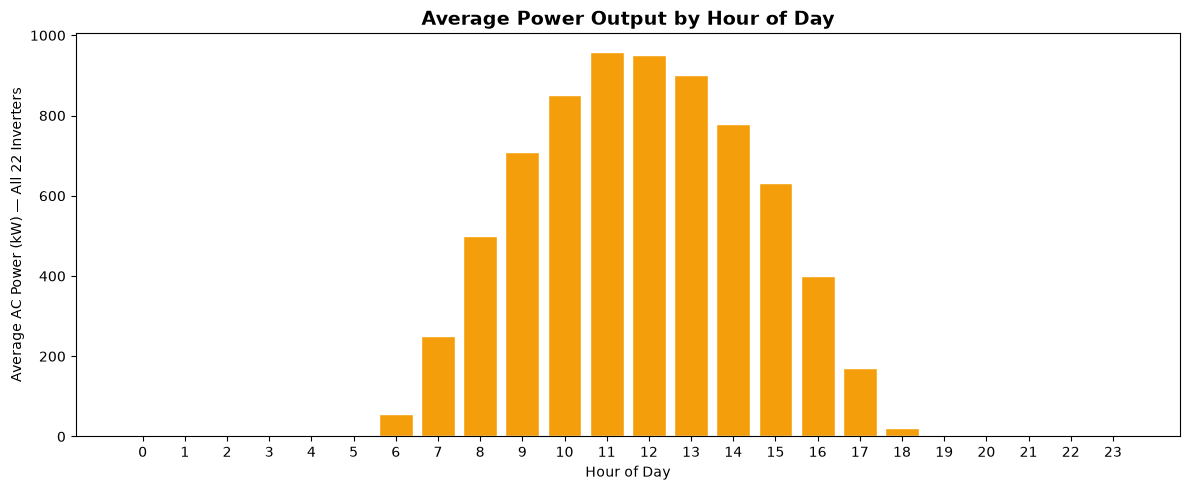

In [ ]:
# Chart 2: Hourly Generation Profile
hourly = gen.groupby('hour')['AC_POWER'].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(hourly.index, hourly.values, color='#F59E0B', edgecolor='white')
ax.set_title("Average Power Output by Hour of Day", fontsize=14, fontweight='bold')
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average AC Power (kW) — All 22 Inverters")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig('../reports/chart2_hourly_profile.png', dpi=150, bbox_inches='tight')
plt.show()

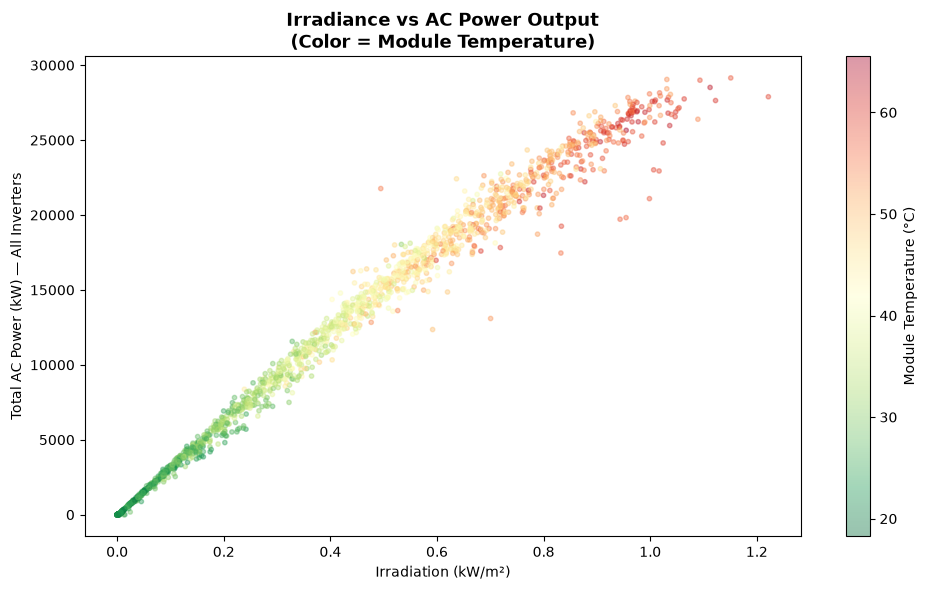

In [23]:
# Chart 3: Irradiance vs AC Output Scatter Plot
daytime = merged[merged['IRRADIATION'] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(daytime['IRRADIATION'], daytime['AC_POWER'], 
                     c=daytime['MODULE_TEMPERATURE'], cmap='RdYlGn_r', 
                     alpha=0.4, s=10)
plt.colorbar(scatter, label='Module Temperature (°C)')
ax.set_title("Irradiance vs AC Power Output\n(Color = Module Temperature)", 
             fontsize=13, fontweight='bold')
ax.set_xlabel("Irradiation (kW/m²)")
ax.set_ylabel("Total AC Power (kW) — All Inverters")
plt.tight_layout()
plt.savefig('../reports/chart3_irradiance_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

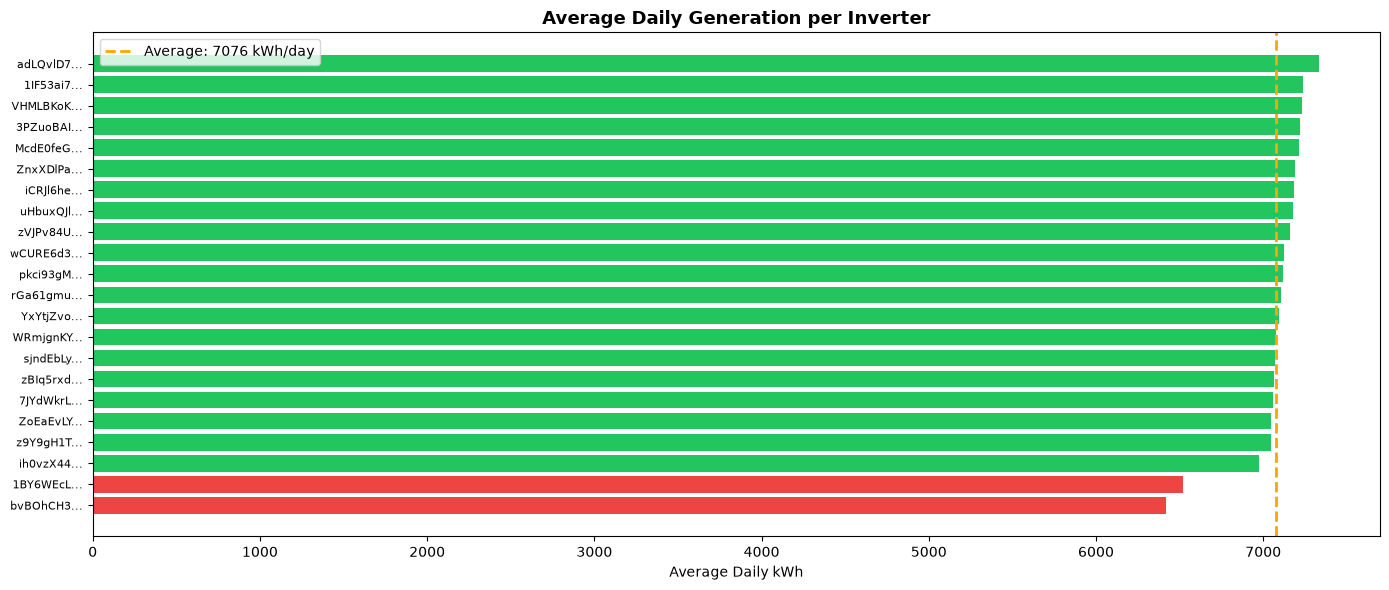

Red bars = inverters performing below 95% of average


In [25]:
# Chart 4: Inverter Comparison
inv_daily = gen.groupby(['date', 'SOURCE_KEY'])['AC_POWER'].sum() * 0.25
inv_avg = inv_daily.groupby('SOURCE_KEY').mean().sort_values()

fig, ax = plt.subplots(figsize=(14, 6))
colors_inv = ['#EF4444' if v < inv_avg.mean() * 0.95 else '#22C55E' for v in inv_avg.values]
ax.barh(range(len(inv_avg)), inv_avg.values, color=colors_inv)
ax.set_yticks(range(len(inv_avg)))
ax.set_yticklabels([k[:8] + '...' for k in inv_avg.index], fontsize=8)
ax.axvline(inv_avg.mean(), color='orange', linestyle='--', linewidth=2, 
           label=f'Average: {inv_avg.mean():.0f} kWh/day')
ax.set_title("Average Daily Generation per Inverter", fontsize=13, fontweight='bold')
ax.set_xlabel("Average Daily kWh")
ax.legend()
plt.tight_layout()
plt.savefig('../reports/chart4_inverter_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Red bars = inverters performing below 95% of average")

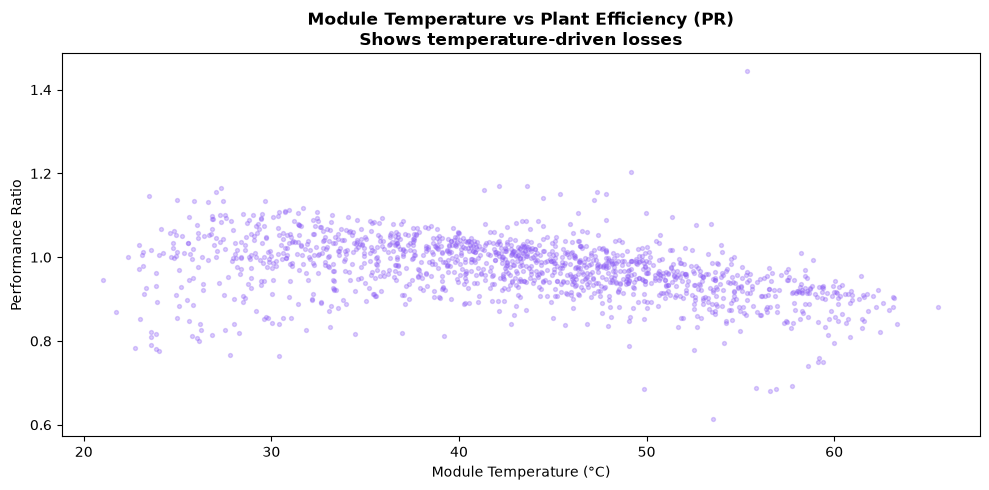

In [26]:
# Chart 5: Module Temperature vs Efficiency
merged_eff = merged.copy()
merged_eff['plant_efficiency'] = merged_eff['AC_POWER'] / (merged_eff['IRRADIATION'] * total_capacity_kw).replace(0, None)
day_data = merged_eff[merged_eff['IRRADIATION'] > 0.1]  # only meaningful irradiance

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(day_data['MODULE_TEMPERATURE'], day_data['plant_efficiency'], 
           alpha=0.3, s=8, color='#8B5CF6')
ax.set_title("Module Temperature vs Plant Efficiency (PR)\nShows temperature-driven losses", 
             fontsize=12, fontweight='bold')
ax.set_xlabel("Module Temperature (°C)")
ax.set_ylabel("Performance Ratio")
plt.tight_layout()
plt.savefig('../reports/chart5_temp_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

LOAD INTO SQLITE FOR SQL QUERIES

In [28]:
import sqlite3
conn = sqlite3.connect('../sql/solar.db')

In [ ]:
# pandas DataFrames and writes it as a table inside the database
gen.to_sql('solar_generation', conn, if_exists='replace', index=False)
weather.to_sql('solar_weather', conn, if_exists='replace', index=False)
merged.to_sql('solar_merged', conn, if_exists='replace', index=False)

3157

In [ ]:
# close connection
conn.close()

NameError: name 'conn' is not defined